Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 120s 1us/step
Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 96s 3s/step - accuracy: 0.7837 - loss: 0.4659 - val_accuracy: 0.9400 - val_loss: 0.1764
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 134s 3s/step - accuracy: 0.9750 - loss: 0.1095 - val_accuracy: 0.9600 - val_loss: 0.1220
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 84s 3s/step - accuracy: 0.9800 - loss: 0.0761 - val_accuracy: 0.9750 - val_loss: 0.0828
Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 140s 5s/step - accuracy: 0.9762 - loss: 0.1008 - val_accuracy: 0.9700 - val_loss: 0.0724
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 59s 2s/step - accuracy: 0.9975 - loss: 0.0441 - val_accuracy: 0.9750 - val_loss: 0.0626
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.9975 - loss: 0.0273 - val_accuracy: 0.9750 - val_loss: 0.0535
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 750ms/step - accuracy: 

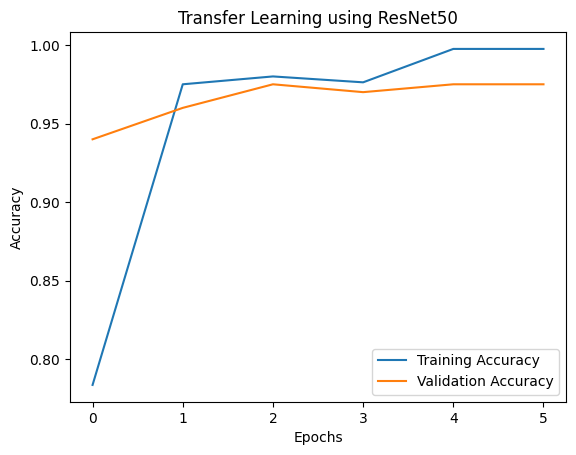

In [2]:

# Step 1: Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

# Step 2: Load Dataset
path = "cats_vs_dogs"

train = tf.keras.utils.image_dataset_from_directory(
    path, validation_split=0.2, subset="training",
    seed=123, image_size=(224,224), batch_size=32
)

test = tf.keras.utils.image_dataset_from_directory(
    path, validation_split=0.2, subset="validation",
    seed=123, image_size=(224,224), batch_size=32
)

# Step 3: Load Pretrained ResNet50
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

# Step 4: Freeze Layers
base_model.trainable = False

# Step 5: Add Classification Layers
inputs = tf.keras.Input(shape=(224,224,3))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
outputs = Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

# Step 6: Compile Model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Step 7: Train with Frozen Layers
h1 = model.fit(train, validation_data=test, epochs=3)

# Step 8: Fine-Tune Last 30 Layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

h2 = model.fit(train, validation_data=test, epochs=3)

# Step 9: Evaluate Model
loss, accuracy = model.evaluate(test)

print("Final Accuracy:", accuracy * 100, "%")
print("Final Loss:", loss)

# Step 10: Compare Performance
print("Frozen Accuracy:",
      max(h1.history["val_accuracy"]) * 100, "%")

print("Fine-Tuned Accuracy:",
      max(h2.history["val_accuracy"]) * 100, "%")

# Step 11: Plot Accuracy
plt.plot(h1.history["accuracy"] + h2.history["accuracy"],
         label="Training Accuracy")
plt.plot(h1.history["val_accuracy"] + h2.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Transfer Learning using ResNet50")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.

Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 108s 4s/step - accuracy: 0.8950 - loss: 0.2441 - val_accuracy: 0.9800 - val_loss: 0.0741
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 93s 4s/step - accuracy: 0.9887 - loss: 0.0479 - val_accuracy: 0.9650 - val_loss: 0.0986
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 143s 4s/step - accuracy: 0.9875 - loss: 0.0396 - val_accuracy: 0.9750 - val_loss: 0.0718
Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 125s 4s/step - accuracy: 0.9912 - loss: 0.0375 - val_accuracy: 0.9800 - val_loss: 0.0531
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 107s 4s/step - accuracy: 0.9987 - loss: 0.0052 - val_accuracy: 0.9850 - val_loss: 0.0343
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 104s 4s/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 0.9800 - val_loss: 0.0303
Before Fine Tuning: 0.9750000238418579
After Fine Tuning: 0.9800000190734863


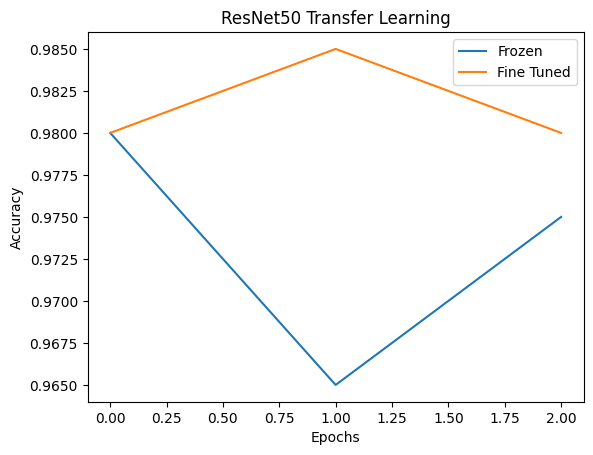

In [3]:
# Step 1: Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt

# Step 2: Load Dataset
train = tf.keras.utils.image_dataset_from_directory(
    'cats_vs_dogs',
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset='training',
    seed=123
)

val = tf.keras.utils.image_dataset_from_directory(
    'cats_vs_dogs',
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset='validation',
    seed=123
)

# Step 3: Load Pretrained ResNet50
base_model = tf.keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# Step 4: Freeze Layers
base_model.trainable = False

# Step 5: Build Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224,224,3)),
    tf.keras.layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    ),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(2, activation='softmax')
])

# Step 6: Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 7: Train Frozen Model
h1 = model.fit(train, validation_data=val, epochs=3)

# Step 8: Fine-Tune Last 10 Layers
base_model.trainable = True

for layer in base_model.layers[:-10]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 9: Train Fine-Tuned Model
h2 = model.fit(train, validation_data=val, epochs=3)

# Step 10: Compare Performance
print("Before Fine Tuning:", h1.history['val_accuracy'][-1])
print("After Fine Tuning:", h2.history['val_accuracy'][-1])

# Step 11: Plot Accuracy
plt.plot(h1.history['val_accuracy'], label='Frozen')
plt.plot(h2.history['val_accuracy'], label='Fine Tuned')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('ResNet50 Transfer Learning')
plt.legend()
plt.show()

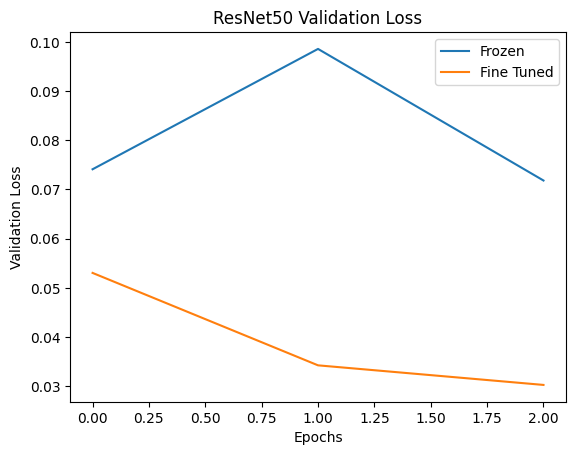

In [4]:
# Plot Validation Loss
plt.plot(h1.history['val_loss'], label='Frozen')
plt.plot(h2.history['val_loss'], label='Fine Tuned')

plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.title('ResNet50 Validation Loss')
plt.legend()
plt.show()